In [ ]:
import math
import time
import random
import pickle

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# -----------------------------
# Utilities
# -----------------------------

def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)

def rolling_mean(x, window=100):
    """Compute a padded rolling mean to align with original length."""
    x = np.asarray(x, dtype=float)
    if x.size == 0:
        return np.array([])
    w = min(window, x.size)
    cumsum = np.cumsum(np.insert(x, 0, 0.0))
    out = (cumsum[w:] - cumsum[:-w]) / float(w)
    pad = np.concatenate([np.full(w-1, np.nan), out])
    return pad

In [ ]:
# ============================================================
# Task 1. Safe Grid World Environment
# ============================================================

UP, DOWN, LEFT, RIGHT = 0, 1, 2, 3
ACTIONS = [UP, DOWN, LEFT, RIGHT]
ACTION_NAMES = {UP: "UP", DOWN: "DOWN", LEFT: "LEFT", RIGHT: "RIGHT"}

class EnvConfig:
    def __init__(
        self,
        grid_n=10,
        start=(0, 0),
        goal=(9, 9),
        hazards=None,
        step_penalty=-0.1,
        random_start=False,
        max_steps=200,
    ):
        if hazards is None:
            hazards = (
                (0,3),(1,1),(1,7),(2,4),(2,8),(3,2),(3,6),
                (4,5),(5,3),(5,8),(6,1),(6,6),(7,4),(8,2),(8,7)
            )
        self.grid_n = grid_n
        self.start = start
        self.goal = goal
        self.hazards = tuple(hazards)
        self.step_penalty = step_penalty
        self.random_start = random_start
        self.max_steps = max_steps

class SafeGridWorld:
    def __init__(self, config):
        self.cfg = config
        self.n = config.grid_n
        self.start_fixed = config.start
        self.goal = config.goal
        self.hazards = set(config.hazards)
        self.random_start = config.random_start
        self.step_penalty = config.step_penalty
        self.max_steps = config.max_steps

        self.state = None
        self.steps = 0

        # Precompute safe cells (exclude goal & hazards)
        self.all_cells = [(r,c) for r in range(self.n) for c in range(self.n)]
        self.safe_cells = [s for s in self.all_cells if (s not in self.hazards and s != self.goal)]

    def reset(self):
        self.steps = 0
        if self.random_start:
            self.state = random.choice(self.safe_cells)
        else:
            self.state = self.start_fixed
        return self.state

    def step(self, action):
        r, c = self.state
        if action == UP:
            nr, nc = r-1, c
        elif action == DOWN:
            nr, nc = r+1, c
        elif action == LEFT:
            nr, nc = r, c-1
        elif action == RIGHT:
            nr, nc = r, c+1
        else:
            raise ValueError("Invalid action")

        # Wall collision: stay in place if out of bounds
        if not (0 <= nr < self.n and 0 <= nc < self.n):
            nr, nc = r, c

        next_state = (nr, nc)
        self.steps += 1

        # Hazard?
        if next_state in self.hazards:
            self.state = next_state
            reward = -10.0
            done = True
            info = {"terminal": "hazard"}
            return next_state, reward, done, info

        # Goal?
        if next_state == self.goal:
            self.state = next_state
            reward = 10.0
            done = True
            info = {"terminal": "goal"}
            return next_state, reward, done, info

        # Continue
        self.state = next_state
        reward = self.step_penalty
        done = (self.steps >= self.max_steps)
        info = {}
        return next_state, reward, done, info

    def render(self):
        grid = [["." for _ in range(self.n)] for __ in range(self.n)]
        for (r,c) in self.hazards:
            grid[r][c] = "H"
        gr, gc = self.goal
        grid[gr][gc] = "G"
        sr, sc = self.state
        grid[sr][sc] = "A"
        return "\n".join(" ".join(row) for row in grid)

In [ ]:
# ============================================================
# Task 2. Q-Learning Baseline (no torch)
# ============================================================

class QLConfig:
    def __init__(
        self,
        alpha=0.1,
        gamma=0.99,
        eps_start=1.0,
        eps_min=0.01,
        eps_decay=0.995,
        episodes=2000,
        max_steps=200,
        seed=123,
    ):
        self.alpha = alpha
        self.gamma = gamma
        self.eps_start = eps_start
        self.eps_min = eps_min
        self.eps_decay = eps_decay
        self.episodes = episodes
        self.max_steps = max_steps
        self.seed = seed

def state_indexer_factory(n):
    def f(s):
        r, c = s
        return r * n + c
    return f

def run_q_learning(env, cfg, verbose=False):
    """
    Tabular Q-learning baseline.
    Returns a dict WITHOUT agent object to keep it pickle-safe.
    """
    set_global_seed(cfg.seed)
    idx = state_indexer_factory(env.n)
    n_states = env.n * env.n
    n_actions = 4
    Q = np.zeros((n_states, n_actions), dtype=np.float32)

    eps = cfg.eps_start
    rewards, lengths, violations, success = [], [], [], []

    t0 = time.time()

    for ep in range(cfg.episodes):
        s = env.reset()
        ep_rew = 0.0
        ep_len = 0
        hazard_count = 0

        for t in range(cfg.max_steps):
            si = idx(s)
            if np.random.rand() < eps:
                a = np.random.randint(n_actions)
            else:
                a = int(np.argmax(Q[si]))

            s_next, r, done, info = env.step(a)
            sni = idx(s_next)

            # Q-learning update
            best_next = 0.0 if done else np.max(Q[sni])
            td_target = r + cfg.gamma * best_next
            td_error = td_target - Q[si, a]
            Q[si, a] += cfg.alpha * td_error

            ep_rew += r
            ep_len += 1
            if "terminal" in info and info["terminal"] == "hazard":
                hazard_count += 1

            s = s_next
            if done:
                break

        rewards.append(ep_rew)
        lengths.append(ep_len)
        violations.append(hazard_count)
        success.append(1 if (s == env.goal) else 0)

        eps = max(cfg.eps_min, eps * cfg.eps_decay)

        if verbose and (ep+1) % 200 == 0:
            print(
                f"EP {ep+1} | R={ep_rew:.2f} | L={ep_len} | "
                f"V={hazard_count} | eps={eps:.3f}"
            )

    t1 = time.time()
    train_speed = cfg.episodes / (t1 - t0 + 1e-9)

    # Metrics over last 25% of episodes
    M_start = int(cfg.episodes * 0.75)
    M = cfg.episodes - M_start
    success_arr = np.asarray(success)
    rewards_arr = np.asarray(rewards, dtype=float)
    lengths_arr = np.asarray(lengths, dtype=float)
    violations_arr = np.asarray(violations, dtype=float)

    success_rate = 100.0 * (np.sum(success_arr[M_start:]) / float(M))
    avg_reward = float(np.mean(rewards_arr[M_start:]))
    avg_len = float(np.mean(lengths_arr[M_start:]))
    total_viol = int(np.sum(violations_arr))

    metrics = {
        "success_rate_%": success_rate,
        "avg_reward": avg_reward,
        "avg_length": avg_len,
        "total_violations": total_viol,
        "train_speed_eps_per_sec": train_speed,
    }

    out = {
        "Q": Q,
        "rewards": rewards_arr,
        "lengths": lengths_arr,
        "violations": violations_arr,
        "success": success_arr,
        "metrics": metrics,
    }
    return out

def plot_task2_curves(results_dict, title_suffix=""):
    """Produce 4 required plots with 100-episode smoothing."""
    rewards = results_dict["rewards"]
    lengths = results_dict["lengths"]
    violations = results_dict["violations"]
    success = results_dict["success"]

    fig, axs = plt.subplots(2, 2, figsize=(12,8))
    axs = axs.ravel()

    axs[0].plot(rolling_mean(rewards, 100))
    axs[0].set_title(f"Training Reward (smoothed){title_suffix}")
    axs[0].set_xlabel("Episode")
    axs[0].set_ylabel("Reward")

    axs[1].plot(rolling_mean(lengths, 100))
    axs[1].set_title(f"Episode Length (smoothed){title_suffix}")
    axs[1].set_xlabel("Episode")
    axs[1].set_ylabel("Steps")

    axs[2].plot(np.cumsum(violations))
    axs[2].set_title(f"Cumulative Safety Violations{title_suffix}")
    axs[2].set_xlabel("Episode")
    axs[2].set_ylabel("Cumulative Violations")

    # Rolling success rate (%)
    win = 100
    sr = []
    for i in range(len(success)):
        lo = max(0, i - win + 1)
        sr.append(100.0 * np.mean(success[lo:i+1]))
    axs[3].plot(sr)
    axs[3].set_title(f"Success Rate Over Time (rolling {win}){title_suffix}")
    axs[3].set_xlabel("Episode")
    axs[3].set_ylabel("Success %")

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# Task 3. Danger map + complete dataset
# ============================================================

def compute_danger_map(env):
    """BFS from all hazards to compute distance-to-hazard map D(s)."""
    from collections import deque
    D = {}
    Q = deque()
    # Initialize with hazards
    for h in env.hazards:
        D[h] = 0
        Q.append((h, 0))
    # BFS
    while Q:
        (r,c), d = Q.popleft()
        for a in ACTIONS:
            if a == UP:
                nr, nc = r-1, c
            elif a == DOWN:
                nr, nc = r+1, c
            elif a == LEFT:
                nr, nc = r, c-1
            else:
                nr, nc = r, c+1
            if 0 <= nr < env.n and 0 <= nc < env.n:
                ns = (nr, nc)
                if ns not in D:
                    D[ns] = d + 1
                    Q.append((ns, d+1))
    return D

def compute_next_state(env, s, a):
    """Deterministic transition without side effects (no reward/termination)."""
    r,c = s
    if a == UP: nr,nc = r-1,c
    elif a == DOWN: nr,nc = r+1,c
    elif a == LEFT: nr,nc = r,c-1
    else: nr,nc = r,c+1
    if not (0 <= nr < env.n and 0 <= nc < env.n):
        nr, nc = r, c
    return (nr,nc)

def build_complete_dataset(env, D_map):
    """Enumerate all valid (state, action) and build 10-dim features + 4-class labels."""
    n = env.n
    X = []
    y = []

    for r in range(n):
        for c in range(n):
            s = (r,c)
            if s in env.hazards or s == env.goal:
                continue
            for a in ACTIONS:
                s_next = compute_next_state(env, s, a)
                d_next = D_map[s_next]
                # Class from D(s')
                if d_next == 0:
                    cls = 0
                elif d_next == 1:
                    cls = 1
                elif d_next == 2:
                    cls = 2
                else:
                    cls = 3

                x_cur = float(r) / float(n)
                y_cur = float(c) / float(n)
                a_onehot = [1 if a == i else 0 for i in range(4)]
                x_n = float(s_next[0]) / float(n)
                y_n = float(s_next[1]) / float(n)
                d_cur = D_map[s]
                f9 = float(d_cur) / 10.0
                f10 = float(d_next) / 10.0

                feat = [x_cur, y_cur] + a_onehot + [x_n, y_n, f9, f10]
                X.append(feat)
                y.append(cls)

    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.int64)
    assert X.shape == (336, 10), f"Expected 336x10, got {X.shape}"
    return X, y

def stratified_splits(X, y, seed=42):
    """70/15/15 stratified split into train/val/test."""
    X_train, X_tmp, y_train, y_tmp = train_test_split(
        X, y, test_size=0.30, random_state=seed, stratify=y
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_tmp, y_tmp, test_size=0.50, random_state=seed, stratify=y_tmp
    )
    return (X_train, y_train), (X_val, y_val), (X_test, y_test)

In [ ]:
# ============================================================
# Task 4. Safety Shield: hand-written MLP (Numpy)
# ============================================================

class ShieldNN:
    """
    Simple 2-hidden-layer MLP with ReLU, implemented in NumPy:
    10 -> hidden -> hidden -> 4
    """
    def __init__(self, in_dim=10, hidden=64, out_dim=4, seed=42):
        set_global_seed(seed)
        self.in_dim = in_dim
        self.hidden = hidden
        self.out_dim = out_dim

        # He initialization
        self.W1 = np.random.randn(in_dim, hidden) * np.sqrt(2.0 / in_dim)
        self.b1 = np.zeros((hidden,), dtype=np.float32)
        self.W2 = np.random.randn(hidden, hidden) * np.sqrt(2.0 / hidden)
        self.b2 = np.zeros((hidden,), dtype=np.float32)
        self.W3 = np.random.randn(hidden, out_dim) * np.sqrt(2.0 / hidden)
        self.b3 = np.zeros((out_dim,), dtype=np.float32)

        self.m = {
            "W1": np.zeros_like(self.W1), "b1": np.zeros_like(self.b1),
            "W2": np.zeros_like(self.W2), "b2": np.zeros_like(self.b2),
            "W3": np.zeros_like(self.W3), "b3": np.zeros_like(self.b3)
        }
        self.v = {k: np.zeros_like(v) for k, v in self.m.items()}
        self.adam_t = 0 

    def relu(x):
        return np.maximum(0.0, x)

    def relu_grad(x):
        return (x > 0).astype(np.float32)

    def softmax(logits):
        logits = logits - np.max(logits, axis=1, keepdims=True)
        exp = np.exp(logits)
        return exp / np.sum(exp, axis=1, keepdims=True)

    def forward(self, X):
        """
        Forward pass, returns intermediate activations for backprop.
        X: (batch, in_dim)
        """
        z1 = X.dot(self.W1) + self.b1
        a1 = ShieldNN.relu(z1)  
        z2 = a1.dot(self.W2) + self.b2
        a2 = ShieldNN.relu(z2) 
        logits = a2.dot(self.W3) + self.b3
        return logits, z1, a1, z2, a2

    def predict_logits(self, X):
        logits, _, _, _, _ = self.forward(X)
        return logits

    def predict_classes(self, X):
        logits = self.predict_logits(X)
        probs = ShieldNN.softmax(logits)
        return np.argmax(probs, axis=1)

def cross_entropy_loss(logits, y):
    """
    logits: (batch, num_classes)
    y: (batch,) int labels
    """
    probs = ShieldNN.softmax(logits)
    N = logits.shape[0]
    log_likelihood = -np.log(probs[np.arange(N), y] + 1e-12)
    return float(np.mean(log_likelihood)), probs

def train_shield_numpy(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden=64,
    lr=1e-3,
    batch_size=32,
    epochs=100,
    seed=42,
    beta1=0.9,
    beta2=0.999,
    adam_eps=1e-8,
):
    """
    Train a multi-class classifier (4 classes) using a hand-written MLP.
    """
    set_global_seed(seed)
    model = ShieldNN(in_dim=10, hidden=hidden, out_dim=4, seed=seed)

    N = X_train.shape[0]
    train_losses = []
    val_losses = []

    for ep in range(epochs):
        # Shuffle training data
        indices = np.arange(N)
        np.random.shuffle(indices)
        X_train_sh = X_train[indices]
        y_train_sh = y_train[indices]

        ep_loss = 0.0
        n_batches = 0

        for start in range(0, N, batch_size):
            end = min(start + batch_size, N)
            xb = X_train_sh[start:end]
            yb = y_train_sh[start:end]
            batch_size_actual = xb.shape[0]

            # Forward
            logits, z1, a1, z2, a2 = model.forward(xb)
            loss, probs = cross_entropy_loss(logits, yb)
            ep_loss += loss
            n_batches += 1

            # Backward: gradient of loss wrt logits
            grad_logits = probs
            grad_logits[np.arange(batch_size_actual), yb] -= 1.0
            grad_logits /= float(batch_size_actual)

            # Gradients for W3, b3
            dW3 = a2.T.dot(grad_logits)
            db3 = np.sum(grad_logits, axis=0)

            # Backprop into a2
            da2 = grad_logits.dot(model.W3.T)
            dz2 = da2 * ShieldNN.relu_grad(z2)

            dW2 = a1.T.dot(dz2)
            db2 = np.sum(dz2, axis=0)

            da1 = dz2.dot(model.W2.T)
            dz1 = da1 * ShieldNN.relu_grad(z1)

            dW1 = xb.T.dot(dz1)
            db1 = np.sum(dz1, axis=0)

            model.adam_t += 1 
            grads = {
                "W1": dW1, "b1": db1,
                "W2": dW2, "b2": db2,
                "W3": dW3, "b3": db3
            }

            for param_name in grads.keys():
                model.m[param_name] = beta1 * model.m[param_name] + (1 - beta1) * grads[param_name]
                model.v[param_name] = beta2 * model.v[param_name] + (1 - beta2) * (grads[param_name] ** 2)
                m_hat = model.m[param_name] / (1 - beta1 ** model.adam_t)
                v_hat = model.v[param_name] / (1 - beta2 ** model.adam_t)
                param = getattr(model, param_name)
                param -= lr * m_hat / (np.sqrt(v_hat) + adam_eps)
                setattr(model, param_name, param)

        train_losses.append(ep_loss / max(1, n_batches))

        # Validation loss
        logits_val, _, _, _, _ = model.forward(X_val)
        val_loss, _ = cross_entropy_loss(logits_val, y_val)
        val_losses.append(val_loss)

    history = {"train_loss": train_losses, "val_loss": val_losses}
    return model, history

def eval_shield_numpy(model, X, y):
    """Evaluate accuracy, per-class accuracy, and confusion matrix."""
    logits = model.predict_logits(X)
    probs = ShieldNN.softmax(logits)
    preds = np.argmax(probs, axis=1)

    acc = 100.0 * float(np.mean(preds == y))
    cm = confusion_matrix(y, preds, labels=[0,1,2,3])

    per_class_acc = []
    for cls in [0,1,2,3]:
        mask = (y == cls)
        if np.sum(mask) == 0:
            per_class_acc.append(float("nan"))
        else:
            per_class_acc.append(100.0 * float(np.mean(preds[mask] == cls)))
    return acc, per_class_acc, cm

def plot_loss_curves(hist):
    plt.figure(figsize=(6,4))
    plt.plot(hist["train_loss"], label="train")
    plt.plot(hist["val_loss"], label="val")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Shield Training Loss (numpy MLP)")
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_confusion(cm, title="Confusion Matrix"):
    import itertools
    plt.figure(figsize=(5,4))
    plt.imshow(cm, interpolation='nearest')
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(4)
    plt.xticks(tick_marks, [0,1,2,3])
    plt.yticks(tick_marks, [0,1,2,3])
    thresh = cm.max() / 2.0
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(
            j, i, format(cm[i, j], "d"),
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black",
        )
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# Task 5. Integration: Safe RL with Shield (numpy)
# ============================================================

class SafeRLConfig:
    def __init__(
        self,
        alpha=0.1,
        gamma=0.99,
        eps_start=1.0,
        eps_min=0.01,
        eps_decay=0.995,
        episodes=1000,
        max_steps=200,
        random_start=True,
        seed=123,
    ):
        self.alpha = alpha
        self.gamma = gamma
        self.eps_start = eps_start
        self.eps_min = eps_min
        self.eps_decay = eps_decay
        self.episodes = episodes
        self.max_steps = max_steps
        self.random_start = random_start
        self.seed = seed

# GLOBAL_D_MAP will be set in main after environment creation
GLOBAL_D_MAP = None

def shield_predict_classes(model, env, state):
    """
    Predict class for each of the 4 actions at a given state,
    using the same 10-dim features as in Task 3.
    """
    n = env.n
    r, c = state
    x_cur, y_cur = float(r)/n, float(c)/n
    feats = []

    d_cur = GLOBAL_D_MAP[state] / 10.0

    for a in ACTIONS:
        s_next = compute_next_state(env, state, a)
        x_n, y_n = float(s_next[0])/n, float(s_next[1])/n
        d_next = GLOBAL_D_MAP[s_next] / 10.0
        a_onehot = [1 if a == i else 0 for i in range(4)]
        feat = [x_cur, y_cur] + a_onehot + [x_n, y_n, d_cur, d_next]
        feats.append(feat)

    X = np.array(feats, dtype=np.float32)
    return model.predict_classes(X)

def run_safe_rl(env, shield_model, Q_init, cfg, threshold, verbose=False):
    """
    Q-learning with a safety shield that may intervene based on predicted class.
    """
    set_global_seed(cfg.seed)
    idx = state_indexer_factory(env.n)
    n_states = env.n * env.n
    n_actions = 4

    if Q_init is not None:
        Q = Q_init.copy()
    else:
        Q = np.zeros((n_states, n_actions), dtype=np.float32)

    eps = cfg.eps_start
    rewards, lengths, violations, success, interventions = [], [], [], [], []

    for ep in range(cfg.episodes):
        s = env.reset()
        ep_rew = 0.0
        ep_len = 0
        hazard_count = 0
        inter_count = 0

        for t in range(cfg.max_steps):
            si = idx(s)
            # Proposed action via epsilon-greedy
            if np.random.rand() < eps:
                a_prop = np.random.randint(n_actions)
            else:
                a_prop = int(np.argmax(Q[si]))

            # Shield classifications
            cls_all = shield_predict_classes(shield_model, env, s)
            cls_prop = cls_all[a_prop]

            # Intervention policy
            if cls_prop > threshold:
                a_exec = a_prop
            else:
                acceptable = [a for a in ACTIONS if cls_all[a] > threshold]
                if len(acceptable) > 0:
                    # pick acceptable action with highest Q (tie-break by action id)
                    qvals = [(Q[si, a], a) for a in acceptable]
                    qvals.sort(key=lambda x: (-x[0], x[1]))
                    a_exec = qvals[0][1]
                else:
                    # no acceptable -> choose among least risky (max class) then highest Q
                    cmax = np.max(cls_all)
                    cand = [a for a in ACTIONS if cls_all[a] == cmax]
                    qvals = [(Q[si, a], a) for a in cand]
                    qvals.sort(key=lambda x: (-x[0], x[1]))
                    a_exec = qvals[0][1]

            if a_exec != a_prop:
                inter_count += 1

            s_next, r, done, info = env.step(a_exec)
            sni = idx(s_next)

            # Q-learning update
            best_next = 0.0 if done else np.max(Q[sni])
            td_target = r + cfg.gamma * best_next
            td_error = td_target - Q[si, a_exec]
            Q[si, a_exec] += cfg.alpha * td_error

            ep_rew += r
            ep_len += 1
            if "terminal" in info and info["terminal"] == "hazard":
                hazard_count += 1

            s = s_next
            if done:
                break

        rewards.append(ep_rew)
        lengths.append(ep_len)
        violations.append(hazard_count)
        success.append(1 if (s == env.goal) else 0)
        interventions.append(inter_count)

        eps = max(cfg.eps_min, eps * cfg.eps_decay)

        if verbose and (ep+1) % 200 == 0:
            print(
                f"[zeta={threshold}] EP {ep+1} | R={ep_rew:.2f} | "
                f"L={ep_len} | V={hazard_count} | I={inter_count} | eps={eps:.3f}"
            )

    return {
        "Q": Q,
        "rewards": np.asarray(rewards, dtype=float),
        "lengths": np.asarray(lengths, dtype=float),
        "violations": np.asarray(violations, dtype=float),
        "success": np.asarray(success, dtype=float),
        "interventions": np.asarray(interventions, dtype=float),
    }

def summarize_lastN(res, N=100):
    """
    Generic summary over last N episodes.
    Works for baseline (no interventions) and safe RL (with interventions).
    """
    rewards = res["rewards"]
    lengths = res["lengths"]
    n = rewards.shape[0]
    if n == 0:
        return {}
    N = min(N, n)

    out = {}
    seg_r = rewards[-N:]
    seg_l = lengths[-N:]
    out["avg_reward"] = float(np.mean(seg_r))
    out["avg_length"] = float(np.mean(seg_l))

    if "success" in res:
        seg_s = res["success"][-N:]
        out["success_rate_%"] = 100.0 * float(np.mean(seg_s))

    if "violations" in res:
        seg_v = res["violations"][-N:]
        out["avg_violation"] = float(np.mean(seg_v))
        out["total_violations"] = int(np.sum(res["violations"]))

    if "interventions" in res:
        seg_i = res["interventions"][-N:]
        out["avg_intervention"] = float(np.mean(seg_i))

    return out

def plot_task5_comparisons(baseline_res, safe_res_list, thresholds):
    """Comparison plots: rewards, per-episode violations, and interventions."""
    # Rewards over time
    plt.figure(figsize=(12,4))
    plt.plot(rolling_mean(baseline_res["rewards"],100), label="Baseline (no shield)")
    for res, th in zip(safe_res_list, thresholds):
        plt.plot(rolling_mean(res["rewards"],100), label=f"Safe RL zeta={th}")
    plt.title("Episode Rewards (smoothed)")
    plt.xlabel("Episode")
    plt.ylabel("Reward")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Safety violations per episode
    plt.figure(figsize=(12,4))
    plt.plot(rolling_mean(baseline_res["violations"],100), label="Baseline (no shield)")
    for res, th in zip(safe_res_list, thresholds):
        plt.plot(rolling_mean(res["violations"],100), label=f"Safe RL zeta={th}")
    plt.title("Safety Violations per Episode (smoothed)")
    plt.xlabel("Episode")
    plt.ylabel("Violations")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Interventions per episode
    plt.figure(figsize=(12,4))
    for res, th in zip(safe_res_list, thresholds):
        plt.plot(rolling_mean(res["interventions"],100), label=f"Interventions zeta={th}")
    plt.title("Shield Interventions per Episode (smoothed)")
    plt.xlabel("Episode")
    plt.ylabel("Interventions")
    plt.legend()
    plt.tight_layout()
    plt.show()


=== Task 2 Metrics Comparison (last 25% episodes) ===
Step Penalty    Success Rate %  Avg Reward  Avg Length  Total Viol   Train Speed
--------------------------------------------------------------------------------
-1.0                     98.20      -7.360       18.00         562      14233.25
-0.1                     97.20       7.751       17.89         513      15887.24


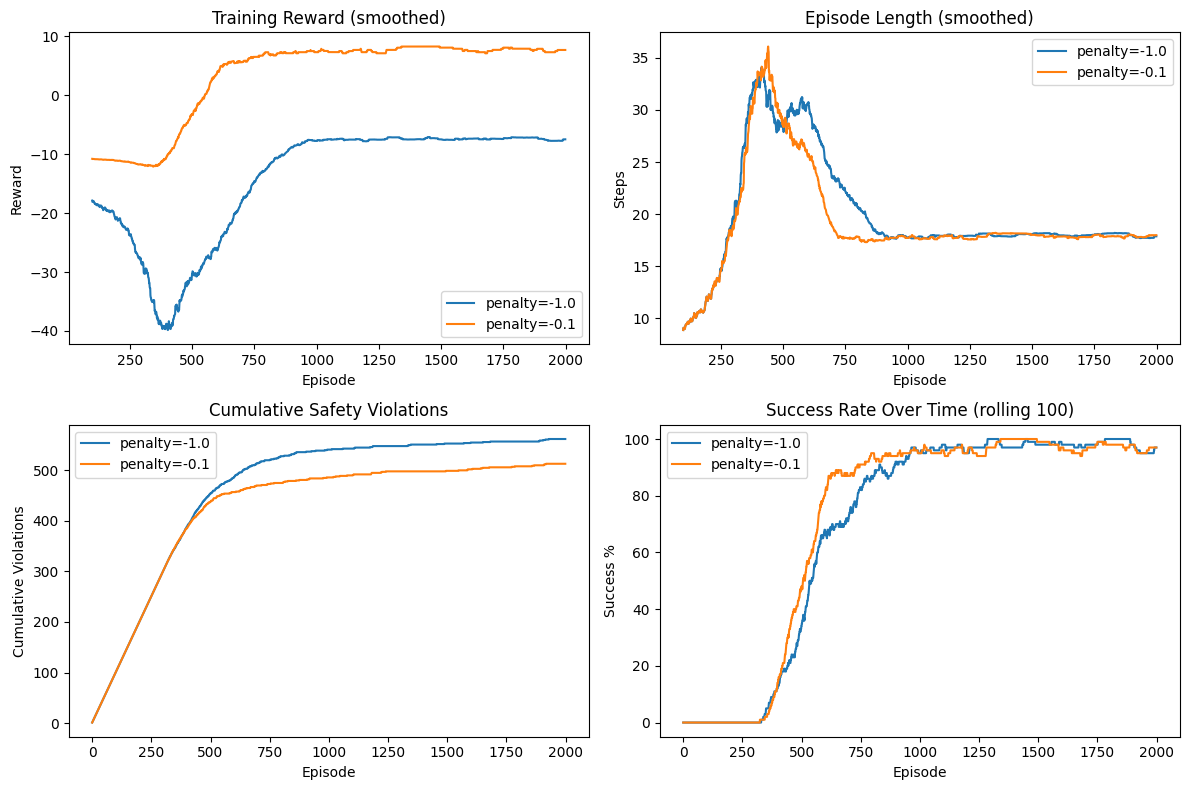


Selected better baseline (by success rate): step_penalty=-1.0
Saved baseline_qtable.pkl


In [ ]:
# ============================================================
# Main: end-to-end demo (can be run as script)
# ============================================================

if __name__ == "__main__":
    # ---------------------------
    # Task 2: Q-learning baseline (two step penalties)
    # ---------------------------
    base_env_cfg1 = EnvConfig(step_penalty=-1.0, random_start=False, max_steps=200)
    env1 = SafeGridWorld(base_env_cfg1)
    ql_cfg = QLConfig(
        alpha=0.1,
        gamma=0.99,
        eps_start=1.0,
        eps_min=0.01,
        eps_decay=0.995,
        episodes=2000,
        max_steps=200,
        seed=123,
    )

    base_env_cfg2 = EnvConfig(step_penalty=-0.1, random_start=False, max_steps=200)
    env2 = SafeGridWorld(base_env_cfg2)
    
    res_p1 = run_q_learning(env1, ql_cfg, verbose=False)
    res_p01 = run_q_learning(env2, ql_cfg, verbose=False)

    def print_task2_comparison_table(res_p1, res_p01, penalty1=-1.0, penalty2=-0.1):
        """
        Print a comparison table for Task 2 metrics of two step penalties.
        Each res_* should be the dict returned by run_q_learning().
        """
        m1 = res_p1["metrics"]
        m2 = res_p01["metrics"]

        header = (
            f"{'Step Penalty':<15}"
            f"{'Success Rate %':>15}"
            f"{'Avg Reward':>12}"
            f"{'Avg Length':>12}"
            f"{'Total Viol':>12}"
            f"{'Train Speed':>14}"
        )
        print("\n=== Task 2 Metrics Comparison (last 25% episodes) ===")
        print(header)
        print("-" * len(header))
  
        def fmt_row(pen, m):
            return (
                f"{pen:<15}"
                f"{m['success_rate_%']:>15.2f}"
                f"{m['avg_reward']:>12.3f}"
                f"{m['avg_length']:>12.2f}"
                f"{m['total_violations']:>12d}"
                f"{m['train_speed_eps_per_sec']:>14.2f}"
            )

        print(fmt_row(penalty1, m1))
        print(fmt_row(penalty2, m2))


    def plot_task2_combined(res_p1, res_p01, label1="penalty=-1.0", label2="penalty=-0.1"):
        """
        Plot 4 panels, each panel contains both step-penalty settings:
        1. Reward (smoothed)
        2. Episode length (smoothed)
        3. Cumulative safety violations
        4. Success rate (rolling window)
        """
        r1, l1, v1, s1 = res_p1["rewards"], res_p1["lengths"], res_p1["violations"], res_p1["success"]
        r2, l2, v2, s2 = res_p01["rewards"], res_p01["lengths"], res_p01["violations"], res_p01["success"]

        fig, axs = plt.subplots(2, 2, figsize=(12, 8))
        axs = axs.ravel()

        # 1. Reward
        axs[0].plot(rolling_mean(r1, 100), label=label1)
        axs[0].plot(rolling_mean(r2, 100), label=label2)
        axs[0].set_title("Training Reward (smoothed)")
        axs[0].set_xlabel("Episode")
        axs[0].set_ylabel("Reward")
        axs[0].legend()

        # 2. Episode length
        axs[1].plot(rolling_mean(l1, 100), label=label1)
        axs[1].plot(rolling_mean(l2, 100), label=label2)
        axs[1].set_title("Episode Length (smoothed)")
        axs[1].set_xlabel("Episode")
        axs[1].set_ylabel("Steps")
        axs[1].legend()

        # 3. Cumulative safety violations
        axs[2].plot(np.cumsum(v1), label=label1)
        axs[2].plot(np.cumsum(v2), label=label2)
        axs[2].set_title("Cumulative Safety Violations")
        axs[2].set_xlabel("Episode")
        axs[2].set_ylabel("Cumulative Violations")
        axs[2].legend()

        # 4. Success rate (rolling window)
        win = 100
        sr1, sr2 = [], []
        for i in range(len(s1)):
            lo = max(0, i - win + 1)
            sr1.append(100.0 * np.mean(s1[lo:i+1]))
        for i in range(len(s2)):
            lo = max(0, i - win + 1)
            sr2.append(100.0 * np.mean(s2[lo:i+1]))

        axs[3].plot(sr1, label=label1)
        axs[3].plot(sr2, label=label2)
        axs[3].set_title(f"Success Rate Over Time (rolling {win})")
        axs[3].set_xlabel("Episode")
        axs[3].set_ylabel("Success %")
        axs[3].legend()

        plt.tight_layout()
        plt.show()

    print_task2_comparison_table(res_p1, res_p01, penalty1=-1.0, penalty2=-0.1)

    plot_task2_combined(res_p1, res_p01, label1="penalty=-1.0", label2="penalty=-0.1")

    better = res_p1 if res_p1["metrics"]["success_rate_%"] > res_p01["metrics"]["success_rate_%"] else res_p01
    better_penalty = -1.0 if better is res_p1 else -0.1
    print(f"\nSelected better baseline (by success rate): step_penalty={better_penalty}")

    with open("baseline_qtable.pkl", "wb") as f:
        pickle.dump(
            {
                "Q": better["Q"],
                "metrics": better["metrics"],
                "step_penalty": better_penalty,
            },
            f,
        )
    print("Saved baseline_qtable.pkl")

In [ ]:
    # ---------------------------
    # Task 3: Complete dataset
    # ---------------------------
    env_data = SafeGridWorld(EnvConfig(step_penalty=-0.1, random_start=False))
    GLOBAL_D_MAP = compute_danger_map(env_data)

    X, y = build_complete_dataset(env_data, GLOBAL_D_MAP)
    print(f"\nDataset shapes: X={X.shape}, y={y.shape} (should be 336 x 10)")
    print("Class distribution:", {cls:int(np.sum(y==cls)) for cls in [0,1,2,3]})

    (X_tr, y_tr), (X_va, y_va), (X_te, y_te) = stratified_splits(X, y, seed=42)
    with open("complete_dataset.pkl", "wb") as f:
        pickle.dump(
            {
                "X_train": X_tr,
                "y_train": y_tr,
                "X_val": X_va,
                "y_val": y_va,
                "X_test": X_te,
                "y_test": y_te,
            },
            f,
        )
    print("Saved complete_dataset.pkl")


Dataset shapes: X=(336, 10), y=(336,) (should be 336 x 10)
Class distribution: {0: 59, 1: 161, 2: 94, 3: 22}
Saved complete_dataset.pkl


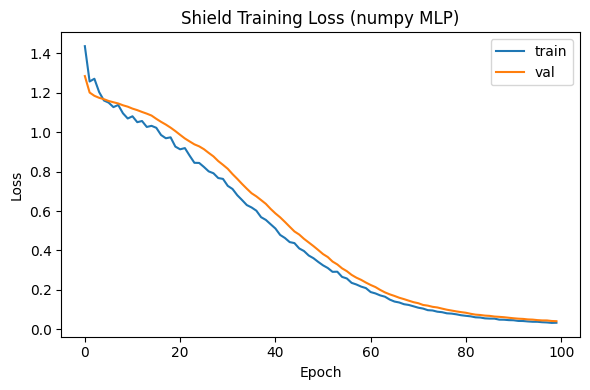


=== Task 4 Validation ===
Overall Acc: 100.00%
Per-class Acc (C0,C1,C2,C3): ['100.00%', '100.00%', '100.00%', '100.00%']


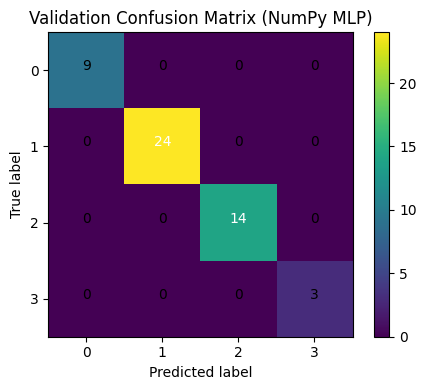


=== Task 4 Test ===
Overall Acc: 100.00%
Per-class Acc (C0,C1,C2,C3): ['100.00%', '100.00%', '100.00%', '100.00%']


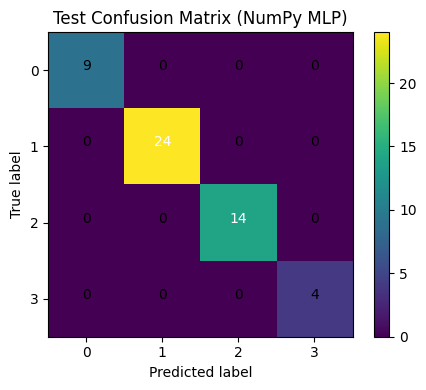

Saved shield_model.pkl


In [ ]:
    # ---------------------------
    # Task 4: Train the safety shield (NumPy MLP)
    # ---------------------------
    model, hist = train_shield_numpy(
        X_tr,
        y_tr,
        X_va,
        y_va,
        hidden=64,
        lr=1e-3,  
        batch_size=32,
        epochs=100,
        seed=42
    )
    plot_loss_curves(hist)

    acc_val, per_cls_val, cm_val = eval_shield_numpy(model, X_va, y_va)
    acc_te, per_cls_te, cm_te = eval_shield_numpy(model, X_te, y_te)

    print("\n=== Task 4 Validation ===")
    print(f"Overall Acc: {acc_val:.2f}%")
    print("Per-class Acc (C0,C1,C2,C3):", [f"{a:.2f}%" for a in per_cls_val])
    plot_confusion(cm_val, title="Validation Confusion Matrix (NumPy MLP)")

    print("\n=== Task 4 Test ===")
    print(f"Overall Acc: {acc_te:.2f}%")
    print("Per-class Acc (C0,C1,C2,C3):", [f"{a:.2f}%" for a in per_cls_te])
    plot_confusion(cm_te, title="Test Confusion Matrix (NumPy MLP)")

    # Save the shield model (numpy weights)
    with open("shield_model.pkl", "wb") as f:
        pickle.dump(model, f)
    print("Saved shield_model.pkl")

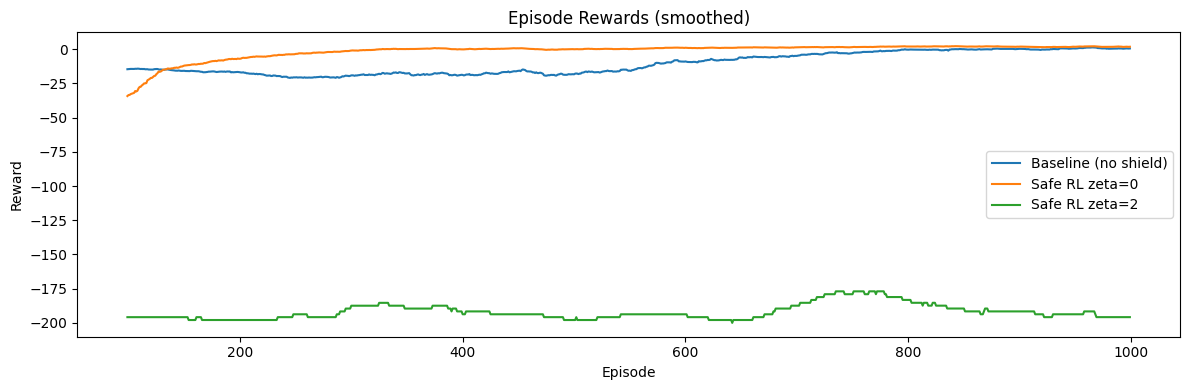

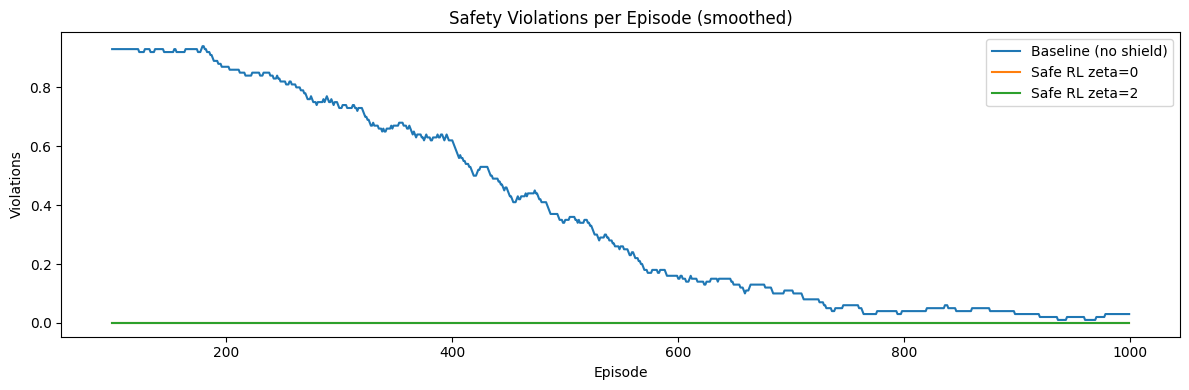

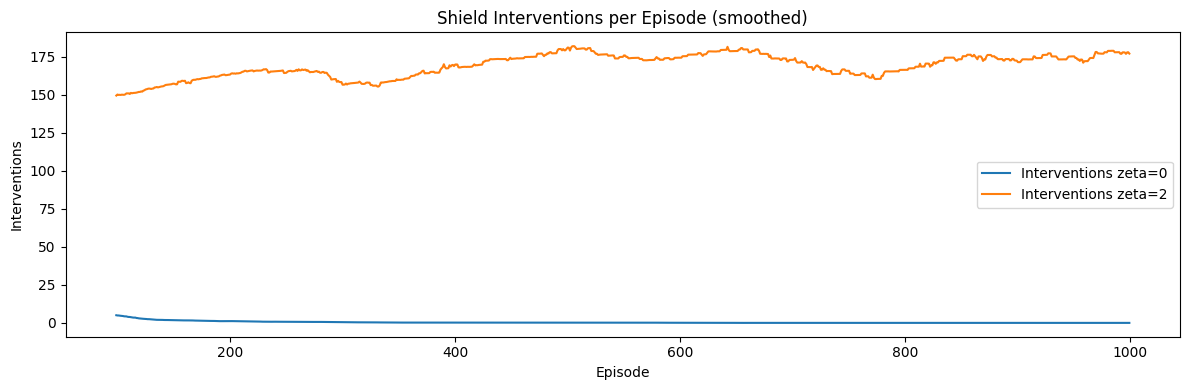


=== Task 5 Summary over last 100 episodes ===
Baseline (no shield): {'avg_reward': 0.53, 'avg_length': 9.87, 'success_rate_%': 97.0, 'avg_violation': 0.03, 'total_violations': 387}
Safe RL zeta=0: {'avg_reward': 1.78, 'avg_length': 9.22, 'success_rate_%': 100.0, 'avg_violation': 0.0, 'total_violations': 0, 'avg_intervention': 0.01}
Safe RL zeta=2: {'avg_reward': -195.8, 'avg_length': 196.02, 'success_rate_%': 2.0, 'avg_violation': 0.0, 'total_violations': 0, 'avg_intervention': 177.06}
Saved safe_rl_results.pkl


In [ ]:
    # ---------------------------
    # Task 5: Integrate shield for Safe RL
    # ---------------------------
    with open("baseline_qtable.pkl", "rb") as f:
        saved = pickle.load(f)
    Q_init = saved["Q"]

    env_safe = SafeGridWorld(
        EnvConfig(step_penalty=saved["step_penalty"], random_start=True, max_steps=200)
    )
    GLOBAL_D_MAP = compute_danger_map(env_safe)

    thresholds = [0, 2]
    safe_cfg = SafeRLConfig(
        alpha=0.1,
        gamma=0.99,
        eps_start=1.0,
        eps_min=0.01,
        eps_decay=0.995,
        episodes=1000,
        max_steps=200,
        random_start=True,
        seed=123,
    )

    baseline_cfg = QLConfig(
        alpha=0.1,
        gamma=0.99,
        eps_start=1.0,
        eps_min=0.01,
        eps_decay=0.995,
        episodes=1000,
        max_steps=200,
        seed=123,
    )
    env_base_compare = SafeGridWorld(
        EnvConfig(step_penalty=saved["step_penalty"], random_start=True, max_steps=200)
    )
    baseline_res = run_q_learning(env_base_compare, baseline_cfg, verbose=False)

    safe_results = []
    for th in thresholds:
        safe_res = run_safe_rl(env_safe, model, Q_init, safe_cfg, threshold=th, verbose=False)
        safe_results.append(safe_res)

    plot_task5_comparisons(baseline_res, safe_results, thresholds)

    print("\n=== Task 5 Summary over last 100 episodes ===")
    print("Baseline (no shield):", summarize_lastN(baseline_res, N=100))
    for th, res in zip(thresholds, safe_results):
        summ = summarize_lastN(res, N=100)
        print(f"Safe RL zeta={th}:", summ)

    # Save experiment artifacts
    to_dump = {
        "thresholds": thresholds,
        "baseline": baseline_res,
        "safe": safe_results,
    }
    with open("safe_rl_results.pkl", "wb") as f:
        pickle.dump(to_dump, f)
    print("Saved safe_rl_results.pkl")